# Case File 04: The Prediction Room
**Objective 4 · Machine learning with Scikit-learn**

**The case.** Can I predict a listing's nightly price from its basic characteristics, and, just as important,
how much should I trust that prediction?

**The witness.** The cleaned Airbnb listings from Case File 01.

**Rules for this notebook:** split first, put all preprocessing inside the pipeline (so cross-validation can't leak),
always beat a baseline, and touch the test set exactly once.

In [9]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

from pathlib import Path
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

Path("../models").mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

df = pd.read_csv("../data/processed/listings_clean.csv")
print(df.shape)

(457, 22)


## 1. Target and features
I predict `log(1 + price)`. Prices are right-skewed, and on a log scale an error of 0.1 means "about 10% off" at any price level.

In [10]:
y = np.log1p(df["price"])
numeric = ["accommodates", "bedrooms", "beds", "minimum_nights", "availability_365",
           "number_of_reviews", "review_scores_rating", "dist_centre_km",
           "host_tenure_years", "host_is_superhost", "instant_bookable", "has_reviews"]
categorical = ["room_type", "neighbourhood_cleansed", "property_type"]
numeric = [c for c in numeric if c in df.columns and df[c].notna().any()]   # drop columns that are empty in this file
print("Numeric features used:", numeric)
X = df[numeric + categorical]

# Split first: nothing below may "see" the test set during fitting
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows")

Numeric features used: ['accommodates', 'bedrooms', 'beds', 'minimum_nights', 'availability_365', 'number_of_reviews', 'review_scores_rating', 'dist_centre_km', 'host_is_superhost', 'has_reviews']
Train: 365 rows | Test: 92 rows


## 2. Preprocessing inside the pipeline
Median-impute and scale numbers; most-frequent-impute and one-hot encode categories (grouping categories with fewer than 20 listings).

In [11]:
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), numeric),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore",
                                               min_frequency=20,
                                               sparse_output=False))]), categorical),
])

## 3. Baseline first, then three real models
5-fold cross-validation on the **training data only**. The baseline always predicts the median, so it tells me what "better than nothing" means.

In [12]:
models = {
    "Baseline (median)": DummyRegressor(strategy="median"),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
}

results, spread = {}, {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")
    results[name], spread[name] = -scores.mean(), scores.std()
    print(f"{name:20s} CV RMSE (log scale): {-scores.mean():.3f} ± {scores.std():.3f}")

Baseline (median)    CV RMSE (log scale): 0.600 ± 0.035
Ridge                CV RMSE (log scale): 0.356 ± 0.013
Random Forest        CV RMSE (log scale): 0.319 ± 0.025
Gradient Boosting    CV RMSE (log scale): 0.328 ± 0.031


## 4. Final evaluation on the untouched test set

In [13]:
best_name = min((k for k in results if "Baseline" not in k), key=results.get)
best = Pipeline([("prep", preprocess), ("model", models[best_name])]).fit(X_train, y_train)
pred = best.predict(X_test)

base = Pipeline([("prep", preprocess), ("model", models["Baseline (median)"])]).fit(X_train, y_train)
base_pred = base.predict(X_test)

def report(name, p):
    return {"model": name,
            "test_RMSE_log": np.sqrt(mean_squared_error(y_test, p)),
            "test_MAE_per_night": mean_absolute_error(np.expm1(y_test), np.expm1(p)),
            "R2": r2_score(y_test, p)}

pd.DataFrame([report("Baseline (median)", base_pred), report(best_name, pred)]).round(3)

,model,test_RMSE_log,test_MAE_per_night,R2
0,Baseline (median),0.575,80.422,-0.003
1,Random Forest,0.254,38.627,0.805


## 5. Residuals: where does the model struggle?

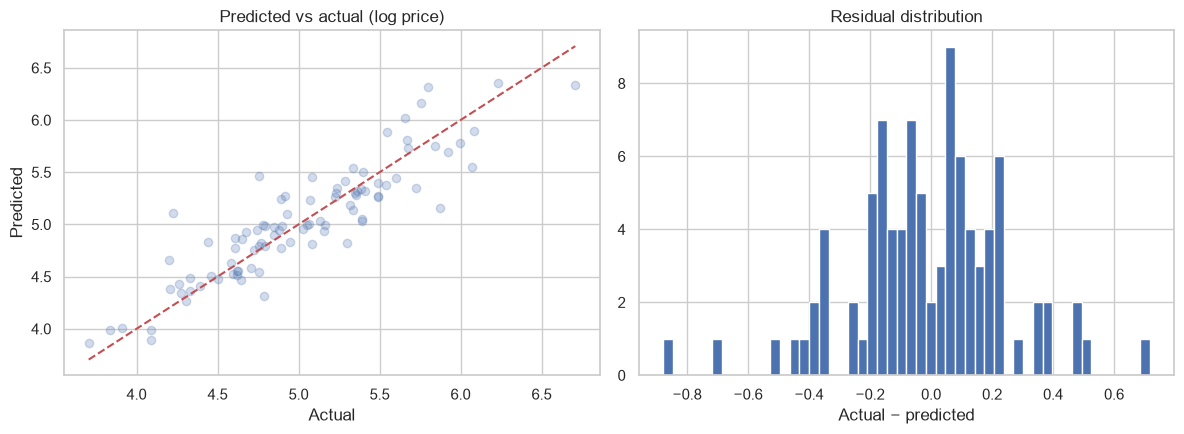

,mean absolute error per night
band,
cheapest 20%,14.7
20-40%,23.3
40-60%,25.6
60-80%,30.2
priciest 20%,97.6


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_test, pred, alpha=0.25)
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
ax[0].set(title="Predicted vs actual (log price)", xlabel="Actual", ylabel="Predicted")
ax[1].hist(y_test - pred, bins=50)
ax[1].set(title="Residual distribution", xlabel="Actual − predicted")
plt.tight_layout()
plt.savefig(FIG / "D_model_diagnostics.png", dpi=200)
plt.show()

# Error by price band: cheap vs expensive listings
bands = pd.qcut(np.expm1(y_test), 5, labels=["cheapest 20%", "20-40%", "40-60%", "60-80%", "priciest 20%"])
err = pd.DataFrame({"band": bands, "abs_err": np.abs(np.expm1(y_test) - np.expm1(pred))})
err.groupby("band", observed=True)["abs_err"].mean().round(1).to_frame("mean absolute error per night")

## 6. Which features actually matter?
Permutation importance is model-agnostic: shuffle one feature on the test set and see how much the error grows.

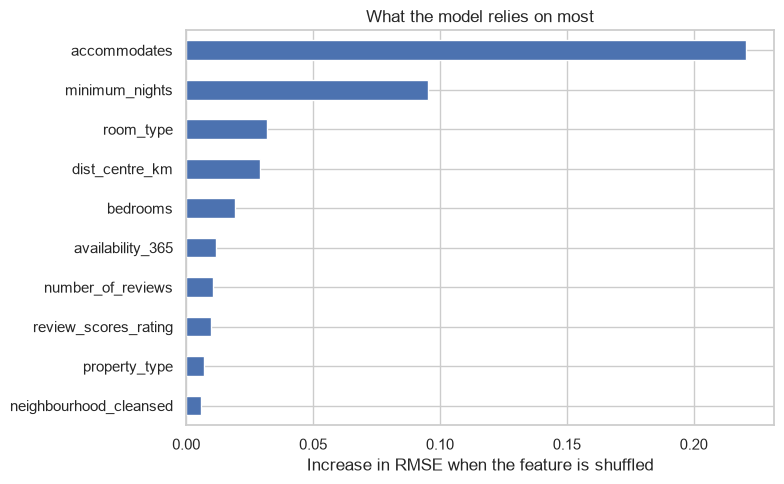

accommodates              0.2206
minimum_nights            0.0952
room_type                 0.0319
dist_centre_km            0.0289
bedrooms                  0.0192
availability_365          0.0117
number_of_reviews         0.0105
review_scores_rating      0.0097
property_type             0.0071
neighbourhood_cleansed    0.0057
dtype: float64

In [15]:
imp = permutation_importance(best, X_test, y_test, n_repeats=10, random_state=42,
                             scoring="neg_root_mean_squared_error")
ranking = pd.Series(imp.importances_mean, index=X_test.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
ranking.head(10).sort_values().plot.barh(ax=ax)
ax.set(title="What the model relies on most", xlabel="Increase in RMSE when the feature is shuffled")
plt.tight_layout()
plt.savefig(FIG / "E_permutation_importance.png", dpi=200)
plt.show()
ranking.head(10).round(4)

In [16]:
joblib.dump(best, "../models/price_model.joblib")
print("Saved ../models/price_model.joblib")

Saved ../models/price_model.joblib


## Honesty box
- **Where the model fails:** the priciest 20% of listings, with a mean error of about $98 per night against about $15 for the cheapest 20%. There are few expensive listings to learn from.
- **How much to trust the scores:** the test set is only 92 listings, and the test RMSE (0.254) is better than the cross-validation RMSE (0.319), so the split may have been favourable. Random Forest and Gradient Boosting differ by less than one standard deviation, so I cannot say one is truly better.
- **What it can't see:** photos, listing description, host reputation beyond a few numbers, and the season.
- **How to use it:** as a *guide* for sanity-checking a price, not as a price-setting oracle.